# **Name: Zohaib Mukhtar**
# **Reg No: SP24-BDS-054**
# **Class: BDS-6A**
# **Subject: Natural Language Processing**
# **Lab 04: Lab Tasks**

## Setup

In [1]:
# Install once if needed: pip install nltk spacy scikit-learn pandas matplotlib deep-translator
# Then run: python -m spacy download en_core_web_sm

import re
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

import nltk
from nltk.corpus import stopwords, movie_reviews, brown
from nltk.stem import PorterStemmer, SnowballStemmer
from nltk.tokenize import sent_tokenize
from nltk.sentiment.vader import SentimentIntensityAnalyzer

import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline

for package in ["stopwords", "movie_reviews", "brown", "punkt", "punkt_tab", "vader_lexicon"]:
    nltk.download(package, quiet=True)

nlp = spacy.load("en_core_web_sm")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 90)

print("Setup finished. spaCy model loaded:", nlp.meta["name"])

Setup finished. spaCy model loaded: core_web_sm


#### What the output shows

The last line confirms that all libraries were imported, the NLTK data was downloaded, and the spaCy model was loaded. From here on every task uses these tools.

## Task 1: Lowercasing Basics and Its Drawbacks

In this task I am checking what happens to a text when I change all of it to lowercase. Lowercasing is a very common first step, but it can also remove useful information. I am solving it in four parts.

### Part a and b: Build a corpus and compare the vocabulary

Here I am writing 12 sentences that contain the same word in different cases, like Apple, apple and APPLE, or US and us. First I split every sentence into words with re.findall(), and I keep the words exactly as they are written. The set of these words is my vocabulary before lowercasing. Then I change every word to lowercase and make a second set, which is my vocabulary after lowercasing. I print the size of both sets. After that I group the words by their lowercase form and print the groups that had more than one spelling, so I can see exactly which words got merged.

In [2]:
corpus = [
    "Apple released a new iPhone and Apple stock went up.",
    "I ate an apple and an orange after lunch.",
    "APPLE is a big company but an apple a day keeps the doctor away.",
    "The US government sent help to us in the storm.",
    "Please tell us about the US election results.",
    "Bill Gates paid the bill on time.",
    "I read the Python manual after I saw a python at the zoo.",
    "Turkey is a beautiful country and a turkey is a big bird.",
    "He works at Amazon and the Amazon river is very long.",
    "The WHO said who should get the vaccine first.",
    "Mark went to see Mark Twain's house and he will mark the date.",
    "Jaguar launched a new car while a jaguar slept in the jungle.",
]

def get_words(text):
    return re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", text)

all_words = [word for sentence in corpus for word in get_words(sentence)]

vocab_before = set(all_words)
vocab_after = set(word.lower() for word in all_words)

print("Number of sentences:", len(corpus))
print("Total words:", len(all_words))
print("Vocabulary size before lowercasing:", len(vocab_before))
print("Vocabulary size after lowercasing:", len(vocab_after))
print("Words lost by merging:", len(vocab_before) - len(vocab_after))
print()

groups = defaultdict(set)
for word in vocab_before:
    groups[word.lower()].add(word)

print("Words that were merged by lowercasing:")
for lower_word, spellings in sorted(groups.items()):
    if len(spellings) > 1:
        print(f"{lower_word} comes from {sorted(spellings)}")

Number of sentences: 12
Total words: 128
Vocabulary size before lowercasing: 86
Vocabulary size after lowercasing: 75
Words lost by merging: 11

Words that were merged by lowercasing:
apple comes from ['APPLE', 'Apple', 'apple']
bill comes from ['Bill', 'bill']
he comes from ['He', 'he']
jaguar comes from ['Jaguar', 'jaguar']
mark comes from ['Mark', 'mark']
python comes from ['Python', 'python']
the comes from ['The', 'the']
turkey comes from ['Turkey', 'turkey']
us comes from ['US', 'us']
who comes from ['WHO', 'who']


#### What the output shows

My corpus has 12 sentences and 128 words in total. The vocabulary has 86 different words before lowercasing and 75 after lowercasing, so lowercasing removed 11 words from the vocabulary.

The list below the numbers shows which words were merged. For example APPLE, Apple and apple became one word, and US and us became one word. Some merges are harmless, like The and the, or He and he, because they are the same word at the start of a sentence. But others are dangerous, like Bill and bill, Turkey and turkey, Python and python, Jaguar and jaguar, Mark and mark, and WHO and who, because the capital letter was telling us that the word is a name or a short form, and now this information is gone.

### Part c: Three examples where lowercasing creates confusion

Here I am picking three sentences from my corpus where the capital letters carry meaning. For each one I print the original sentence, the lowercase sentence, and the words that look the same after lowercasing. This shows how two different meanings become one and the same word.

In [3]:
examples = [
    ("The US government sent help to us in the storm.", "us", "US is the country, us is the pronoun"),
    ("Apple released a new iPhone and Apple stock went up.", "apple", "Apple is the company (the fruit is apple)"),
    ("The WHO said who should get the vaccine first.", "who", "WHO is the health organization, who is the question word"),
]

for sentence, word, meaning in examples:
    lowered = sentence.lower()
    count_before = len(re.findall(r"\b" + word + r"\b", sentence, flags=re.IGNORECASE))
    print("Original :", sentence)
    print("Lowercase:", lowered)
    print("Word checked:", word, "| appears", count_before, "time(s) and now every copy looks identical")
    print("Meaning lost:", meaning)
    print()

Original : The US government sent help to us in the storm.
Lowercase: the us government sent help to us in the storm.
Word checked: us | appears 2 time(s) and now every copy looks identical
Meaning lost: US is the country, us is the pronoun

Original : Apple released a new iPhone and Apple stock went up.
Lowercase: apple released a new iphone and apple stock went up.
Word checked: apple | appears 2 time(s) and now every copy looks identical
Meaning lost: Apple is the company (the fruit is apple)

Original : The WHO said who should get the vaccine first.
Lowercase: the who said who should get the vaccine first.
Word checked: who | appears 2 time(s) and now every copy looks identical
Meaning lost: WHO is the health organization, who is the question word



#### What the output shows

Each block shows one sentence in two forms. In the first one, US and us were two different words, a country and a pronoun, but after lowercasing the sentence reads the us government sent help to us, and both look exactly the same. In the second one, the company Apple and the fruit apple (which only the capital letter separates) become one word. In the third one, WHO the organization and who the question word become the same word.

In every example the word appears 2 times and after lowercasing the two copies cannot be told apart anymore, so a program can no longer know which meaning was meant.

Here I am also testing the same problem on a real tool. I run spaCy's named entity recognizer on a sentence with normal capital letters, and then on the same sentence in lowercase. I print the entities each version finds.

In [4]:
test_sentences = [
    "Apple released a new iPhone in the US last Friday.",
    "apple released a new iphone in the us last friday.",
]

for sentence in test_sentences:
    doc = nlp(sentence)
    print(sentence)
    print("Entities found:", [(ent.text, ent.label_) for ent in doc.ents])
    print()

Apple released a new iPhone in the US last Friday.
Entities found: [('Apple', 'ORG'), ('US', 'GPE'), ('last Friday', 'DATE')]

apple released a new iphone in the us last friday.
Entities found: [('apple', 'ORG'), ('us', 'GPE'), ('last friday', 'DATE')]



#### What the output shows

With normal capital letters spaCy finds three entities in the sentence. Apple is an ORG (a company), US is a GPE (a country) and last Friday is a DATE. After lowercasing, the same words are written apple, us and last friday. In this run spaCy still labeled all three, because the sentence has strong clues around the words, like the verb released and the word in before us.

So the test shows a smaller damage than I expected for this one clear sentence. But the risk is still real, because this model leans on context and capital letters together, and a shorter or less clear text, like a headline with just the word apple, gives it no clue at all. This is why I should avoid lowercasing before NER.

### Part d: Which NLP tasks can be harmed by lowercasing

Lowercasing can hurt several NLP tasks, because capital letters often carry meaning. I will explain the three tasks that the lab names.

**Named Entity Recognition (NER)** is harmed the most. A model uses capital letters as a strong clue that a word is a name. After lowercasing, Apple (company), Bill Gates (person) and Turkey (country) look like normal words, so the model cannot tell them apart from apple, bill and turkey. My spaCy test above still found the entities, but only because the sentence had many other clues, and a short text with a single word gives the model nothing else to use.

**Sentiment analysis** can be harmed too. Writers use capital letters to show strong emotion, so a review that says THIS IS TERRIBLE is stronger than this is terrible. Lowercasing removes that signal. Capital letters can also separate words like WHO and who, or US and us.

**Search** can be harmed because the same word can mean two different things. If someone searches for the company Apple or the programming language Python, a lowercased index will also return results about the fruit and the snake. On the other side, lowercasing helps search when people type in different cases, so it is a trade off.

In short, lowercasing makes the vocabulary smaller and the model simpler, but it throws away information, so I should use it only when case does not matter for my task.

## Task 2: Noise Removal Pipeline

In this task I am cleaning raw social media text with regular expressions. I will write one function for each type of noise, join them into one pipeline, test what happens when the order changes, and look for places where the cleaning goes too far. I am solving it in four parts.

### Part a: Create a noisy dataset

Here I am writing 17 fake tweets and reviews by hand. Together they contain web links, @mentions, #hashtags, emojis, HTML tags and messy extra spaces. I also added special items like C++, $100, 3.5 hours, an email address and R&D, because I want to see later whether the cleaning damages them. I store everything in a list and print the number of entries with the first few entries.

In [5]:
noisy_data = [
    "OMG!!! Just got the new iPhone \U0001F60D\U0001F60D check https://t.co/aB12xY now @Apple #blessed",
    "<p>Great service!!   Will   visit again</p> @CafeRoma #yum \U0001F60B",
    "Learning C++ and Python this semester #coding #CS101 https://bit.ly/3xYz",
    "Paid $100 for these headphones... totally worth it!!! \U0001F3A7 www.shopnow.com/deal",
    "@john_doe you should read this <b>amazing</b> article http://news.com/a?id=5 #news",
    "Battery life is   terrible \U0001F621\U0001F621 don't buy this phone!!! #fail",
    "<div class='review'>Best pizza in town!</div> \U0001F355\U0001F355 #foodie @PizzaHub",
    "Flight delayed AGAIN by 3.5 hours \U0001F624 @AirlineX #worstairline https://t.co/zz99",
    "Email me at sara_k@mail.com for the e-book, it's free!!",
    "Loved the movie... 10/10 would watch again \U0001F3AC #movienight",
    "<br>Customer support was rude.<br>   Never again!!! @ShopCo",
    "Our R&D team built a new AI model in .NET and C# \U0001F680 #tech",
    "Stock is up 5% today!!! Bought 20 shares at $45.50 \U0001F60E #investing",
    "     Too   many    spaces   here   and   there     ",
    "Check out www.example.org and https://example.com/page?x=1&y=2 for more details",
    "The food was cold \U0001F976 & the waiter was slow... 2/5 stars @Diner #disappointed",
    "<a href='http://x.com'>click here</a> to win $1000 NOW!!! \U0001F381",
]

print("Number of entries:", len(noisy_data))
print()
for number, text in enumerate(noisy_data[:4], start=1):
    print(f"{number}. {text!r}")

Number of entries: 17

1. 'OMG!!! Just got the new iPhone 😍😍 check https://t.co/aB12xY now @Apple #blessed'
2. '<p>Great service!!   Will   visit again</p> @CafeRoma #yum 😋'
3. 'Learning C++ and Python this semester #coding #CS101 https://bit.ly/3xYz'
4. 'Paid $100 for these headphones... totally worth it!!! 🎧 www.shopnow.com/deal'


#### What the output shows

The dataset has 17 entries. The first four entries show different kinds of noise at once. The first has a link, a mention, a hashtag and two emojis, the second has HTML paragraph tags and a lot of extra spaces, the third has C++ with two hashtags and a short link, and the fourth has $100, three dots and a link that starts with www.

The numbers like \U0001F60D in my code are Unicode codes of emojis, and Python shows them as the real emoji picture when it prints them.

### Part b: One regex function for each noise type

Here I am writing a separate small function for every kind of noise, so each one does exactly one job.

remove_html replaces anything between a less than sign and a greater than sign with a space. remove_urls deletes words that start with http, https or www. remove_mentions deletes an @ sign with the word after it. handle_hashtags keeps the word and only deletes the hash sign, because the word itself is often useful. remove_emojis deletes characters from the emoji ranges of Unicode. remove_punctuation deletes everything that is not a letter, a digit or a space. normalize_whitespace changes many spaces into one and trims the two ends.

After that I test each function alone on one sentence, so I can see what it does.

In [6]:
def remove_html(text):
    return re.sub(r"<[^>]+>", " ", text)

def remove_urls(text):
    return re.sub(r"https?://\S+|www\.\S+", "", text)

def remove_mentions(text):
    return re.sub(r"@\w+", "", text)

def handle_hashtags(text):
    return re.sub(r"#(\w+)", r"\1", text)

def remove_emojis(text):
    emoji_pattern = re.compile(
        "[\U0001F300-\U0001FAFF\U00002600-\U000027BF\U0001F000-\U0001F2FF\U0000FE0F]+",
        flags=re.UNICODE
    )
    return emoji_pattern.sub("", text)

def remove_punctuation(text):
    return re.sub(r"[^\w\s]", "", text)

def normalize_whitespace(text):
    return re.sub(r"\s+", " ", text).strip()

sample = noisy_data[0]
print("Original      :", sample)
print("remove_html   :", remove_html(sample))
print("remove_urls   :", remove_urls(sample))
print("remove_mentions:", remove_mentions(sample))
print("handle_hashtags:", handle_hashtags(sample))
print("remove_emojis :", remove_emojis(sample))
print("remove_punctuation:", remove_punctuation(sample))

Original      : OMG!!! Just got the new iPhone 😍😍 check https://t.co/aB12xY now @Apple #blessed
remove_html   : OMG!!! Just got the new iPhone 😍😍 check https://t.co/aB12xY now @Apple #blessed
remove_urls   : OMG!!! Just got the new iPhone 😍😍 check  now @Apple #blessed
remove_mentions: OMG!!! Just got the new iPhone 😍😍 check https://t.co/aB12xY now  #blessed
handle_hashtags: OMG!!! Just got the new iPhone 😍😍 check https://t.co/aB12xY now @Apple blessed
remove_emojis : OMG!!! Just got the new iPhone  check https://t.co/aB12xY now @Apple #blessed
remove_punctuation: OMG Just got the new iPhone  check httpstcoaB12xY now Apple blessed


#### What the output shows

Each line shows what one function does alone on the first tweet. remove_html changed nothing here, because this tweet has no HTML tags. remove_urls deleted the link and left a double space behind. remove_mentions deleted @Apple. handle_hashtags changed #blessed to blessed. remove_emojis deleted the two emojis.

The last line is the most interesting. remove_punctuation removed the exclamation marks, but it also removed the characters : / and . inside the link, so the link turned into one strange word, httpstcoaB12xY. It also deleted the @ and # signs and kept the words Apple and blessed. This is a good hint that the order of the steps matters.

### Part c: Combine into clean_text and test the order

Here I am joining all functions into one function called clean_text(). It takes the text and a list of steps, and it runs the steps one by one in the order of the list. My normal order is HTML, URLs, mentions, hashtags, emojis, punctuation, whitespace.

To test the order, I make two other lists. In the second one punctuation is removed first. In the third one whitespace is normalized first. I run all three orders on all 17 texts and count how many outputs are different from my normal order. Then I print three texts where the outputs changed.

In [7]:
default_order = [remove_html, remove_urls, remove_mentions, handle_hashtags,
                 remove_emojis, remove_punctuation, normalize_whitespace]

def clean_text(text, steps=default_order):
    for step in steps:
        text = step(text)
    return text

punctuation_first = [remove_punctuation, remove_html, remove_urls, remove_mentions,
                     handle_hashtags, remove_emojis, normalize_whitespace]

whitespace_first = [normalize_whitespace, remove_html, remove_urls, remove_mentions,
                    handle_hashtags, remove_emojis, remove_punctuation]

normal_output = [clean_text(text, default_order) for text in noisy_data]
punct_output = [clean_text(text, punctuation_first) for text in noisy_data]
space_output = [clean_text(text, whitespace_first) for text in noisy_data]

changed_punct = [i for i in range(len(noisy_data)) if normal_output[i] != punct_output[i]]
changed_space = [i for i in range(len(noisy_data)) if normal_output[i] != space_output[i]]

print("Texts changed when punctuation goes first:", len(changed_punct), "out of", len(noisy_data))
print("Texts changed when whitespace goes first :", len(changed_space), "out of", len(noisy_data))
print()

for i in changed_punct[:3]:
    print("Original         :", noisy_data[i])
    print("Normal order     :", normal_output[i])
    print("Punctuation first:", punct_output[i])
    print()

i = changed_space[0]
print("Whitespace first example")
print("Normal order    :", repr(normal_output[i]))
print("Whitespace first:", repr(space_output[i]))

Texts changed when punctuation goes first: 12 out of 17
Texts changed when whitespace goes first : 15 out of 17

Original         : OMG!!! Just got the new iPhone 😍😍 check https://t.co/aB12xY now @Apple #blessed
Normal order     : OMG Just got the new iPhone check now blessed
Punctuation first: OMG Just got the new iPhone check httpstcoaB12xY now Apple blessed

Original         : <p>Great service!!   Will   visit again</p> @CafeRoma #yum 😋
Normal order     : Great service Will visit again yum
Punctuation first: pGreat service Will visit againp CafeRoma yum

Original         : Learning C++ and Python this semester #coding #CS101 https://bit.ly/3xYz
Normal order     : Learning C and Python this semester coding CS101
Punctuation first: Learning C and Python this semester coding CS101 httpsbitly3xYz

Whitespace first example
Normal order    : 'OMG Just got the new iPhone check now blessed'
Whitespace first: 'OMG Just got the new iPhone  check  now  blessed'


#### What the output shows

Yes, the order changes the output. When punctuation was removed first, 12 of the 17 texts came out different. When whitespace was normalized first, 15 of the 17 texts came out different.

The first example shows why. With punctuation first, the link lost its colon and slashes before the URL function could see it, so httpstcoaB12xY stayed in the text. In the second example, the HTML tags lost their angle brackets, and the letters p stayed on both ends of the sentence as pGreat and againp. In the third example the link was not removed again. So the URL and HTML functions must always run before the punctuation function.

The last example shows the order of whitespace. If I normalize the spaces first, the later steps remove words and leave new double spaces behind. So the whitespace step has to be the last one.

### Part d: Table of 5 examples and the over cleaning problem

Here I am building a pandas table with five examples, showing the text before cleaning and after cleaning with my normal order. I chose the texts that contain C++, $100, an email, R&D and a price with decimals.

After the table, I check seven special items one by one. For each item I look at the texts that contain it and test whether the item is still there after cleaning. If it is gone, that is a case of over cleaning.

In [8]:
chosen = [2, 3, 8, 11, 12]
table = pd.DataFrame({
    "Before cleaning": [noisy_data[i] for i in chosen],
    "After cleaning": [normal_output[i] for i in chosen],
})
display(table)

print()
special_items = ["C++", "$100", "3.5", "R&D", "sara_k@mail.com", "don't", "$45.50"]
for item in special_items:
    for i, text in enumerate(noisy_data):
        if item in text:
            survived = item in normal_output[i]
            print(f"{item:<18} survived cleaning: {survived} | after: {normal_output[i]!r}")
            break

,Before cleaning,After cleaning
0,Learning C++ and Python this semester #coding #CS101 https://bit.ly/3xYz,Learning C and Python this semester coding CS101
1,Paid $100 for these headphones... totally worth it!!! 🎧 www.shopnow.com/deal,Paid 100 for these headphones totally worth it
2,"Email me at sara_k@mail.com for the e-book, it's free!!",Email me at sara_kcom for the ebook its free
3,Our R&D team built a new AI model in .NET and C# 🚀 #tech,Our RD team built a new AI model in NET and C tech
4,Stock is up 5% today!!! Bought 20 shares at $45.50 😎 #investing,Stock is up 5 today Bought 20 shares at 4550 investing



C++                survived cleaning: False | after: 'Learning C and Python this semester coding CS101'
$100               survived cleaning: False | after: 'Paid 100 for these headphones totally worth it'
3.5                survived cleaning: False | after: 'Flight delayed AGAIN by 35 hours worstairline'
R&D                survived cleaning: False | after: 'Our RD team built a new AI model in NET and C tech'
sara_k@mail.com    survived cleaning: False | after: 'Email me at sara_kcom for the ebook its free'
don't              survived cleaning: False | after: 'Battery life is terrible dont buy this phone fail'
$45.50             survived cleaning: False | after: 'Stock is up 5 today Bought 20 shares at 4550 investing'


#### What the output shows

The table shows five texts before and after cleaning. The links, hashtags signs, emojis and extra spaces are gone, which is what I wanted. But some useful information was destroyed too, and this is called over cleaning. The seven checks at the bottom show it clearly.

C++ became C, so the name of the programming language was changed to another language. $100 became 100, so the currency sign was lost and the number could mean anything. 3.5 became 35 and $45.50 became 4550, so the decimal point was removed and the numbers are now wrong by a factor of ten or a hundred. R&D became RD. The email sara_k@mail.com became sara_kcom, because the mention function cut it in the middle. And don't became dont, which is not a real word.

So removing every symbol is too strong. A better pipeline would keep the signs that are inside numbers and names, like the dot in 3.5, the dollar sign before a number, the plus signs in C++ and the apostrophe in don't.

## Task 3: Stop Word Removal and Its Effect on Vocabulary

In this task I am removing stop words from a real dataset of movie reviews and measuring what changes. I am solving it in four parts.

### Part a: Load NLTK's English stop word list

Here I am loading the English stop words from NLTK into a list. I print the first 20 words and the total size of the list. I also make a set copy of the list, because checking a word inside a set is much faster than checking it inside a list.

In [9]:
stop_list = stopwords.words("english")
stop_set = set(stop_list)

print("First 20 stop words:")
print(stop_list[:20])
print()
print("Total number of stop words:", len(stop_list))

First 20 stop words:
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']

Total number of stop words: 198


#### What the output shows

The first 20 words are small everyday words like a, about, above, after, again and against, and the list is sorted in alphabetical order. The list has 198 words in total in my version of NLTK. Some of them are short forms like aren't and the pieces ain and aren, which come from words that were split at the apostrophe.

### Part b: Compare the dataset before and after removal

Here I am loading 500 movie reviews from NLTK, 250 negative and 250 positive. I split every review into sentences with sent_tokenize(), and then I split each sentence into lowercase words using a regex that keeps small words like don't. Next I remove the stop words from every sentence.

I measure three things before and after removal. The first is the total token count, the second is the vocabulary size (the number of different words), and the third is the average sentence length in tokens. I show the result in one small table.

In [10]:
neg_ids = movie_reviews.fileids("neg")[:250]
pos_ids = movie_reviews.fileids("pos")[:250]
reviews = [movie_reviews.raw(file_id) for file_id in neg_ids + pos_ids]

def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

sentences_all = [sentence for review in reviews for sentence in sent_tokenize(review)]
tokens_per_sentence = [tokenize(sentence) for sentence in sentences_all]
tokens_per_sentence = [tokens for tokens in tokens_per_sentence if len(tokens) > 0]

filtered_per_sentence = [[word for word in tokens if word not in stop_set] for tokens in tokens_per_sentence]

tokens_before = [word for tokens in tokens_per_sentence for word in tokens]
tokens_after = [word for tokens in filtered_per_sentence for word in tokens]

summary = pd.DataFrame({
    "Measure": ["Total tokens", "Vocabulary size", "Average sentence length"],
    "Before removal": [len(tokens_before), len(set(tokens_before)),
                       round(np.mean([len(t) for t in tokens_per_sentence]), 2)],
    "After removal": [len(tokens_after), len(set(tokens_after)),
                      round(np.mean([len(t) for t in filtered_per_sentence]), 2)],
}, dtype=object)

print("Reviews used:", len(reviews))
print("Sentences used:", len(tokens_per_sentence))
print()
display(summary)

removed_share = round((1 - len(tokens_after) / len(tokens_before)) * 100, 1)
print()
print("Share of all tokens that were stop words:", removed_share, "%")

Reviews used: 500
Sentences used: 16209



,Measure,Before removal,After removal
0,Total tokens,310107,168694
1,Vocabulary size,22440,22256
2,Average sentence length,19.13,10.41



Share of all tokens that were stop words: 45.6 %


#### What the output shows

I used 500 reviews, which gave 16,209 sentences. Removing stop words had a very large effect on the number of tokens, but a very small effect on the vocabulary.

The total tokens went from 310,107 to 168,694, so 45.6 percent of all the words in the reviews were stop words. The average sentence length went from 19.13 tokens to 10.41 tokens, almost half. But the vocabulary went from 22,440 only to 22,256, which is a drop of just 184 words. This makes sense, because the stop word list has only 198 words, so it cannot remove many different words, but those words are used again and again, so they make up almost half of the text.

### Part c: Bar charts of the top 15 words

Here I am counting the words with Counter and drawing two horizontal bar charts side by side. The left chart shows the 15 most frequent words before removal, and the right chart shows the 15 most frequent words after removal.

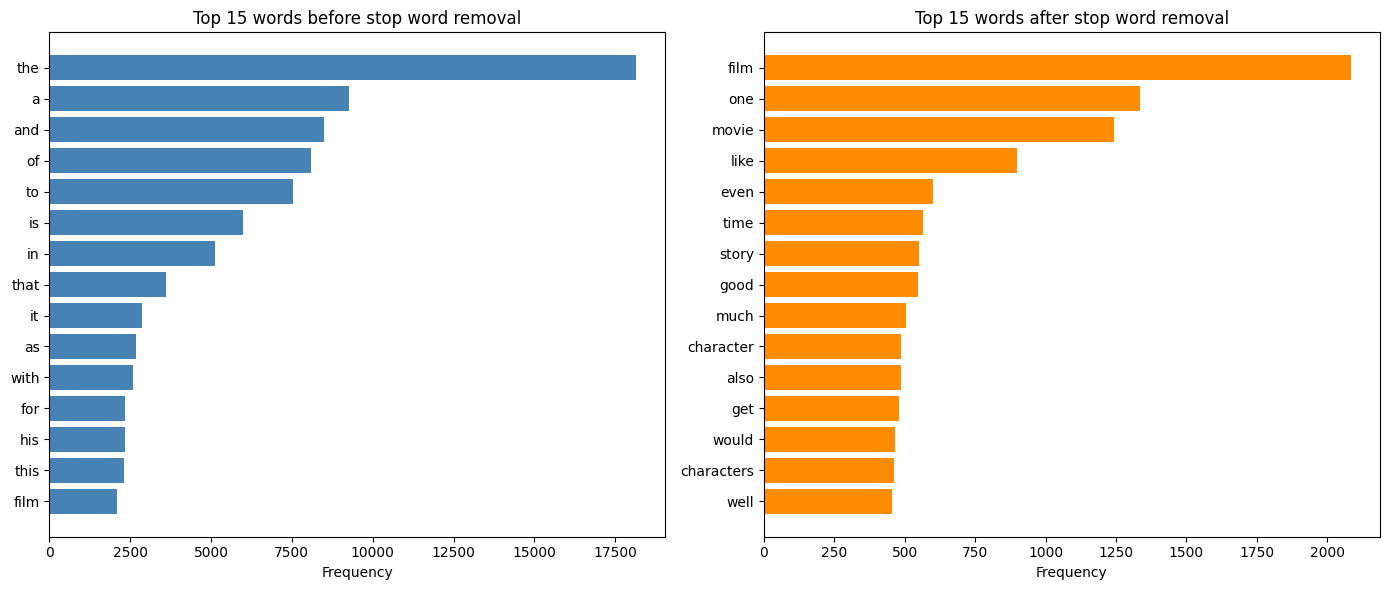

Top 5 before: [('the', 18139), ('a', 9272), ('and', 8506), ('of', 8107), ('to', 7522)]
Top 5 after : [('film', 2083), ('one', 1335), ('movie', 1243), ('like', 897), ('even', 601)]


In [11]:
top_before = Counter(tokens_before).most_common(15)
top_after = Counter(tokens_after).most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

words, counts = zip(*top_before)
axes[0].barh(words[::-1], counts[::-1], color="steelblue")
axes[0].set_title("Top 15 words before stop word removal")
axes[0].set_xlabel("Frequency")

words, counts = zip(*top_after)
axes[1].barh(words[::-1], counts[::-1], color="darkorange")
axes[1].set_title("Top 15 words after stop word removal")
axes[1].set_xlabel("Frequency")

plt.tight_layout()
plt.show()

print("Top 5 before:", top_before[:5])
print("Top 5 after :", top_after[:5])

#### What the output shows

The left chart shows the top 15 words before removal. The top five are the, a, and, of and to, which are all stop words. These words tell us nothing about the topic of the reviews.

The right chart shows the top 15 after removal. Now the top five are film, one, movie, like and even. These words show what the text is about, so the chart is much more useful. Still, film, one and movie appear in nearly every review, so they say little about whether a review is good or bad. This is the reason I make my own list in the next part.

### Part d: My own custom stop word list

Here I am making a custom list for movie reviews. I add 12 words and remove 11 words from the NLTK list, and I write the reason for every choice in a table.

I add words that appear in almost every movie review and say nothing about whether the review is good or bad, like movie and film. I remove words from the list that change the sentiment, like not, no and very, because deleting them would damage the meaning.

After building the list, I print its size, and I print the new top 10 words.

In [12]:
words_to_add = {
    "movie": "appears in nearly every review, so it says nothing about opinion",
    "movies": "same reason as movie",
    "film": "domain word that appears everywhere in movie reviews",
    "films": "same reason as film",
    "one": "very common filler word like in one of the best",
    "also": "connecting word with no sentiment",
    "even": "filler word with no topic meaning",
    "get": "very common verb with no topic meaning",
    "would": "modal verb that fills sentences without adding opinion",
    "could": "modal verb that fills sentences without adding opinion",
    "story": "domain word that every review talks about",
    "character": "domain word that every review talks about",
}

words_to_remove = {
    "not": "negation, removing it flips the sentiment",
    "no": "negation, as in no good",
    "nor": "negation word",
    "don't": "negation, as in don't like",
    "doesn't": "negation, as in doesn't work",
    "didn't": "negation, as in didn't enjoy",
    "isn't": "negation, as in isn't funny",
    "wasn't": "negation, as in wasn't good",
    "very": "intensifier that changes the strength of an opinion",
    "too": "intensifier, as in too long or too slow",
    "but": "contrast word that shows the opinion turns around",
}

rows = [(word, "added", reason) for word, reason in words_to_add.items()]
rows += [(word, "removed", reason) for word, reason in words_to_remove.items()]
display(pd.DataFrame(rows, columns=["Word", "Action", "Reason"]))

custom_stop_set = (stop_set - set(words_to_remove)) | set(words_to_add)

print()
print("Default list size:", len(stop_set))
print("Custom list size :", len(custom_stop_set))
print("Words removed that were really in the default list:", sum(w in stop_set for w in words_to_remove), "of", len(words_to_remove))

custom_tokens = [word for tokens in tokens_per_sentence for word in tokens if word not in custom_stop_set]
print()
print("Token count with custom list:", len(custom_tokens))
print("Top 10 words with custom list:", Counter(custom_tokens).most_common(10))

,Word,Action,Reason
0,movie,added,"appears in nearly every review, so it says nothing about opinion"
1,movies,added,same reason as movie
2,film,added,domain word that appears everywhere in movie reviews
3,films,added,same reason as film
4,one,added,very common filler word like in one of the best
5,also,added,connecting word with no sentiment
6,even,added,filler word with no topic meaning
7,get,added,very common verb with no topic meaning
8,would,added,modal verb that fills sentences without adding opinion
9,could,added,modal verb that fills sentences without adding opinion



Default list size: 198
Custom list size : 199
Words removed that were really in the default list: 11 of 11

Token count with custom list: 165643
Top 10 words with custom list: [('but', 1960), ('not', 1260), ('like', 897), ('no', 595), ('time', 566), ('good', 548), ('much', 505), ('characters', 461), ('well', 455), ('very', 452)]


#### What the output shows

The table lists my 12 added words and 11 removed words with the reason for each one. Words like movie, film, one and story are added, because every review uses them and they do not help to tell a good review from a bad one. Words like not, no, nor, don't, didn't, very, too and but are taken out of the stop list, because they change the meaning of a sentence.

The default list has 198 words and my custom list has 199, because I added 12 and removed 11. All 11 words that I removed were really in the default list.

The top 10 words with the custom list are now but, not, like, no, time, good, much, characters, well and very. Many of them carry opinion, for example not, no, good, well and very, so this list is better for a task like sentiment analysis. The plural characters is still there because I only added the singular character.

## Task 4: Risks of Stop Word Removal (Sentiment, MT, Chatbots)

In this task I am looking at cases where removing stop words blindly gives wrong results. I check sentiment, machine translation and chatbot intent, and then I propose a safer strategy. I am solving it in four parts.

### Part 1: Negation and sentiment

Here I am writing 5 sentences that contain negation. I remove the NLTK stop words from each one, and I score both the original and the reduced version with VADER, which is a ready made sentiment tool in NLTK. The score is called compound and goes from minus one (very negative) to plus one (very positive). I call a score above 0.05 positive, below minus 0.05 negative, and anything in between neutral. Then I check whether the label changed.

In [13]:
sia = SentimentIntensityAnalyzer()

def label_of(score):
    if score > 0.05:
        return "positive"
    if score < -0.05:
        return "negative"
    return "neutral"

def remove_stop_words(text, stop_words):
    return " ".join(word for word in tokenize(text) if word not in stop_words)

negation_sentences = [
    "The movie was not good.",
    "I am never happy with this service.",
    "This is no problem at all.",
    "The food is not bad.",
    "I do not like this phone.",
]

rows = []
for sentence in negation_sentences:
    reduced = remove_stop_words(sentence, stop_set)
    score_before = sia.polarity_scores(sentence)["compound"]
    score_after = sia.polarity_scores(reduced)["compound"] if reduced else 0.0
    rows.append({
        "Original": sentence,
        "After removal": reduced,
        "Score before": score_before,
        "Score after": score_after,
        "Label before": label_of(score_before),
        "Label after": label_of(score_after),
        "Changed": label_of(score_before) != label_of(score_after),
    })

negation_table = pd.DataFrame(rows)
display(negation_table)
print()
print("Sentences where the sentiment label changed:", int(negation_table["Changed"].sum()), "out of", len(negation_table))

,Original,After removal,Score before,Score after,Label before,Label after,Changed
0,The movie was not good.,movie good,-0.3412,0.4404,negative,positive,True
1,I am never happy with this service.,never happy service,-0.4585,-0.4585,negative,negative,False
2,This is no problem at all.,problem,-0.5994,-0.4019,negative,negative,False
3,The food is not bad.,food bad,0.4310,-0.5423,positive,negative,True
4,I do not like this phone.,like phone,-0.2755,0.3612,negative,positive,True



Sentences where the sentiment label changed: 3 out of 5


#### What the output shows

The sentiment label changed for 3 of the 5 sentences. The movie was not good is negative at first, but after removal only movie good is left, which VADER reads as positive. The food is not bad was positive and became negative, because bad was left alone without its not. I do not like this phone was negative and became positive (like phone).

I never happy with this service did not change, because never is not in the NLTK stop word list, so it stayed in the sentence. This is no problem at all stayed negative, but note that VADER already gave a negative score to the original sentence, so this one was not a flip caused by the removal. A human reads no problem as something positive, so VADER itself gets this phrase wrong.

The main point is that stop words like not and no are in the NLTK list, so removing them can turn the meaning of a sentence into its opposite.

### Part 2: Machine translation into Urdu

Here I am taking 3 English sentences, removing the stop words from each, and translating both the original and the reduced version into Urdu. The code first tries to use Google Translate through the deep_translator library. If there is no internet, or the service does not answer, it uses the Urdu text that I saved in a dictionary, so the cell can still run anywhere. I print the English text next to its Urdu translation.

In [14]:
mt_sentences = [
    "I do not want to go to the market today.",
    "She is the best teacher in the school.",
    "Where is the book that you gave to me?",
]

saved_translations = {
    "I do not want to go to the market today.": "میں آج بازار نہیں جانا چاہتا۔",
    "want go market today": "آج مارکیٹ جانا چاہتے ہیں۔",
    "She is the best teacher in the school.": "وہ اسکول کی بہترین استاد ہے۔",
    "best teacher school": "بہترین ٹیچر اسکول",
    "Where is the book that you gave to me?": "وہ کتاب کہاں ہے جو آپ نے مجھے دی تھی؟",
    "book gave": "کتاب دی",
}

def to_urdu(text):
    try:
        from deep_translator import GoogleTranslator
        return GoogleTranslator(source="en", target="ur").translate(text), "live translator"
    except Exception:
        return saved_translations.get(text, "no saved translation"), "saved copy"

for sentence in mt_sentences:
    reduced = remove_stop_words(sentence, stop_set)
    urdu_original, source_a = to_urdu(sentence)
    urdu_reduced, source_b = to_urdu(reduced)
    print("English original :", sentence)
    print("Urdu original    :", urdu_original, f"({source_a})")
    print("English reduced  :", reduced)
    print("Urdu reduced     :", urdu_reduced, f"({source_b})")
    print()

English original : I do not want to go to the market today.
Urdu original    : میں آج بازار نہیں جانا چاہتا۔ (saved copy)
English reduced  : want go market today
Urdu reduced     : آج مارکیٹ جانا چاہتے ہیں۔ (saved copy)



English original : She is the best teacher in the school.
Urdu original    : وہ اسکول کی بہترین استاد ہے۔ (saved copy)
English reduced  : best teacher school
Urdu reduced     : بہترین ٹیچر اسکول (saved copy)

English original : Where is the book that you gave to me?
Urdu original    : وہ کتاب کہاں ہے جو آپ نے مجھے دی تھی؟ (saved copy)
English reduced  : book gave
Urdu reduced     : کتاب دی (saved copy)



#### What the output shows

The Urdu text in this output comes from my saved copy, because the cell uses the saved text when the live translator cannot be reached. The reduced English sentences lose important words, and the Urdu loses them too.

In the first sentence, I do not want to go to the market today becomes want go market today. The original Urdu has the word نہیں (not), but the reduced Urdu says that someone wants to go to the market. The meaning is now the opposite of the original.

In the second sentence, She is the best teacher in the school becomes best teacher school. The Urdu of the reduced sentence is just three words next to each other. It does not say who the teacher is and it is not a full sentence anymore.

In the third sentence, Where is the book that you gave to me? becomes book gave. The question is gone and the Urdu says something like gave a book, so the meaning is completely distorted. So for translation, stop words must stay, because they hold the grammar that a translator needs.

### Part 3: Chatbot intent

Here I am writing 5 chatbot queries and removing their stop words. To show the damage, I wrote a very small intent detector with simple rules. It looks at the words in a query and gives back an intent name. For example, if the query has cancel and also not, it gives cancel_subscription_only, but if it has only cancel, it gives cancel_everything.

I run the detector on the original query and on the reduced query, and I compare the two intents.

In [15]:
def detect_intent(text):
    words = tokenize(text)
    has_not = "not" in words or any(word.endswith("n't") for word in words)
    if "cancel" in words and has_not:
        return "cancel_subscription_only"
    if "cancel" in words:
        return "cancel_everything"
    if "charged" in words and has_not:
        return "avoid_charge"
    if "charged" in words:
        return "billing_issue"
    if "status" in words and "order" in words:
        return "order_status"
    if "change" in words and "address" in words:
        return "change_address"
    return "unknown"

chatbot_queries = [
    "How to not be charged?",
    "What is the status of my order?",
    "I want to cancel my subscription but not the account.",
    "Can I change my delivery address?",
    "Why was I charged twice?",
]

rows = []
for query in chatbot_queries:
    reduced = remove_stop_words(query, stop_set)
    intent_before = detect_intent(query)
    intent_after = detect_intent(reduced)
    rows.append({
        "Query": query,
        "After removal": reduced,
        "Intent before": intent_before,
        "Intent after": intent_after,
        "Damaged": intent_before != intent_after,
    })

chatbot_table = pd.DataFrame(rows)
display(chatbot_table)
print()
print("Queries where the intent was damaged:", int(chatbot_table["Damaged"].sum()), "out of", len(chatbot_table))

,Query,After removal,Intent before,Intent after,Damaged
0,How to not be charged?,charged,avoid_charge,billing_issue,True
1,What is the status of my order?,status order,order_status,order_status,False
2,I want to cancel my subscription but not the account.,want cancel subscription account,cancel_subscription_only,cancel_everything,True
3,Can I change my delivery address?,change delivery address,change_address,change_address,False
4,Why was I charged twice?,charged twice,billing_issue,billing_issue,False



Queries where the intent was damaged: 2 out of 5


#### What the output shows

The intent was damaged in 2 of the 5 queries. How to not be charged became only charged, so the bot sees billing_issue instead of avoid_charge, and it would answer a question about a charge when the user wants to stop it. I want to cancel my subscription but not the account became want cancel subscription account, so the bot sees cancel_everything. That is the worst case, because it could cancel the user's account by mistake.

The other three queries kept their intent, because their meaning sits in content words like status, order, change, address and charged twice. So blind removal does not always break a chatbot, but it breaks exactly the queries that depend on a small word like not or but.

### Part 4: A safe stop word strategy

Here I am making a safe stop word list. I start from the NLTK list and take out the words that carry meaning for sentiment and intent. These are the negation words (not, no, nor and the short forms like don't) and the intensifiers and contrast words (very, too, but, against, only). Words like never are not in the NLTK list at all, so they already survive.

Then I run the five sentences from Part 1 again, with three versions of each sentence: the original, the one with the normal NLTK list, and the one with my safe list. I print the sentiment label of all three, and I also test the chatbot queries again with the safe list.

In [16]:
keep_words = {"not", "no", "nor", "very", "too", "but", "against", "only"}
keep_words |= {word for word in stop_set if word.endswith("n't")}
safe_stop_set = stop_set - keep_words

print("Default list size:", len(stop_set))
print("Safe list size   :", len(safe_stop_set))
print("Words I kept in the text:", len(keep_words))
print()

rows = []
for sentence in negation_sentences:
    naive = remove_stop_words(sentence, stop_set)
    safe = remove_stop_words(sentence, safe_stop_set)
    rows.append({
        "Original": sentence,
        "Label original": label_of(sia.polarity_scores(sentence)["compound"]),
        "Naive removal": naive,
        "Label naive": label_of(sia.polarity_scores(naive)["compound"]) if naive else "neutral",
        "Safe removal": safe,
        "Label safe": label_of(sia.polarity_scores(safe)["compound"]) if safe else "neutral",
    })

safe_table = pd.DataFrame(rows)
safe_table["Naive correct"] = safe_table["Label original"] == safe_table["Label naive"]
safe_table["Safe correct"] = safe_table["Label original"] == safe_table["Label safe"]
display(safe_table)

print()
print("Sentences with the correct label using the naive list:", int(safe_table["Naive correct"].sum()), "out of 5")
print("Sentences with the correct label using the safe list :", int(safe_table["Safe correct"].sum()), "out of 5")

print()
print("Chatbot queries again with the safe list:")
for query in chatbot_queries:
    reduced = remove_stop_words(query, safe_stop_set)
    print(f"{query:<55} reduced: {reduced:<40} intent: {detect_intent(reduced)} (original intent: {detect_intent(query)})")

Default list size: 198
Safe list size   : 172
Words I kept in the text: 26



,Original,Label original,Naive removal,Label naive,Safe removal,Label safe,Naive correct,Safe correct
0,The movie was not good.,negative,movie good,positive,movie not good,negative,False,True
1,I am never happy with this service.,negative,never happy service,negative,never happy service,negative,True,True
2,This is no problem at all.,negative,problem,negative,no problem,negative,True,True
3,The food is not bad.,positive,food bad,negative,food not bad,positive,False,True
4,I do not like this phone.,negative,like phone,positive,not like phone,negative,False,True



Sentences with the correct label using the naive list: 2 out of 5
Sentences with the correct label using the safe list : 5 out of 5

Chatbot queries again with the safe list:
How to not be charged?                                  reduced: not charged                              intent: avoid_charge (original intent: avoid_charge)
What is the status of my order?                         reduced: status order                             intent: order_status (original intent: order_status)
I want to cancel my subscription but not the account.   reduced: want cancel subscription but not account intent: cancel_subscription_only (original intent: cancel_subscription_only)
Can I change my delivery address?                       reduced: change delivery address                  intent: change_address (original intent: change_address)
Why was I charged twice?                                reduced: charged twice                            intent: billing_issue (original intent: billing_issue)

#### What the output shows

My safe list has 172 words, which is 26 fewer than the NLTK list. The 26 words I kept are 8 meaning words (not, no, nor, very, too, but, against, only) and 18 short negative forms like don't and wasn't.

With the safe list the sentiment label was correct for all 5 sentences, compared with only 2 of 5 for the normal list. For example the movie was not good now becomes movie not good, which is negative again, and the food is not bad becomes food not bad, which is positive again.

The chatbot test also improved. All 5 queries now keep the same intent as the original. How to not be charged becomes not charged, and the cancel query keeps the words but not, so the bot understands that only the subscription must be cancelled. So keeping negation words in the text is a simple and safe strategy.

## Task 5: Hands On with the Porter Stemmer

In this task I am testing how the Porter stemmer behaves on different kinds of words, and where it makes mistakes. I am solving it in four parts.

### Part a and b: Stem 40 words and judge each result

Here I am writing a list of 40 words. It has plain inflected forms (running, studies), derived forms (happily, generalization), irregular words (better, was, feet) and some words that I expect to cause trouble (university, universe, organ, general, generous).

For every word I also write its true base word, called the lemma, for example was belongs to be and better belongs to good. I call a stem Correct when it is the same as the stem of the true base word, because then all forms of one word end up together. Otherwise I call it Incorrect. I print the table as Word, Stem, Base word, Verdict, and then the number of correct stems.

In [17]:
porter = PorterStemmer()

base_words = {
    "running": "run", "runs": "run", "ran": "run", "studies": "study", "studying": "study",
    "studied": "study", "happily": "happy", "happiness": "happy", "generalization": "generalize",
    "generalize": "generalize", "better": "good", "best": "good", "was": "be", "were": "be",
    "is": "be", "caresses": "caress", "ponies": "pony", "relational": "relate",
    "conditional": "condition", "flies": "fly", "flying": "fly", "university": "university",
    "universe": "universe", "universal": "universal", "organization": "organize", "organ": "organ",
    "argued": "argue", "arguing": "argue", "argument": "argue", "meetings": "meeting",
    "wolves": "wolf", "feet": "foot", "children": "child", "easily": "easy", "operate": "operate",
    "operating": "operate", "operation": "operate", "general": "general", "generous": "generous",
    "generate": "generate",
}

words = list(base_words.keys())

rows = []
for word in words:
    stem = porter.stem(word)
    correct_stem = porter.stem(base_words[word])
    rows.append({
        "Word": word,
        "Stem": stem,
        "Base word": base_words[word],
        "Verdict": "Correct" if stem == correct_stem else "Incorrect",
    })

stem_table = pd.DataFrame(rows)
print("Number of words:", len(words))
display(stem_table)
print()
print(stem_table["Verdict"].value_counts())

Number of words: 40


,Word,Stem,Base word,Verdict
0,running,run,run,Correct
1,runs,run,run,Correct
2,ran,ran,run,Incorrect
3,studies,studi,study,Correct
4,studying,studi,study,Correct
5,studied,studi,study,Correct
6,happily,happili,happy,Incorrect
7,happiness,happi,happy,Correct
8,generalization,gener,generalize,Correct
9,generalize,gener,generalize,Correct



Verdict
Correct      28
Incorrect    12
Name: count, dtype: int64


#### What the output shows

The Porter stemmer gave a correct stem for 28 of the 40 words and an incorrect stem for 12. By my rule, a stem is correct when it equals the stem of the true base word.

The correct ones are mostly regular forms. Running and runs become run, studies, studying and studied all become studi, and generalization and generalize both become gener. Notice that studi, poni and fli are not real words, but they are still counted as correct, because every form of the same word goes to the same stem.

The incorrect ones are the irregular words and some special endings. Ran, was, were, is, better, best, feet and children are not changed in a useful way, because the stemmer only cuts endings and has no dictionary. Happily becomes happili but happiness becomes happi, argument stays argument but argued becomes argu, wolves becomes wolv, and easily becomes easili.

### Part c: Over stemming and under stemming

Here I am finding the two kinds of stemming errors with code, using my base word list.

Over stemming means that words with different base words end up with the same stem. I group the words by their stem, and I print every group that contains more than one base word.

Under stemming means that words with the same base word end up with different stems. I group the words by their base word, and I print every group that has more than one stem.

In [18]:
stem_groups = defaultdict(list)
base_groups = defaultdict(list)

for word in words:
    stem_groups[porter.stem(word)].append(word)
    base_groups[base_words[word]].append(word)

print("OVER STEMMING: different base words, same stem")
over_count = 0
for stem, group in stem_groups.items():
    different_bases = set(base_words[w] for w in group)
    if len(different_bases) > 1:
        over_count += 1
        print(f"  stem '{stem}' is shared by {group}")

print()
print("UNDER STEMMING: same base word, different stems")
under_count = 0
for base, group in base_groups.items():
    different_stems = set(porter.stem(w) for w in group)
    if len(different_stems) > 1:
        under_count += 1
        print(f"  base word '{base}' gives {[(w, porter.stem(w)) for w in group]}")

print()
print("Over stemming groups found:", over_count)
print("Under stemming groups found:", under_count)

OVER STEMMING: different base words, same stem


  stem 'gener' is shared by ['generalization', 'generalize', 'general', 'generous', 'generate']
  stem 'univers' is shared by ['university', 'universe', 'universal']
  stem 'organ' is shared by ['organization', 'organ']

UNDER STEMMING: same base word, different stems
  base word 'run' gives [('running', 'run'), ('runs', 'run'), ('ran', 'ran')]
  base word 'happy' gives [('happily', 'happili'), ('happiness', 'happi')]
  base word 'good' gives [('better', 'better'), ('best', 'best')]
  base word 'be' gives [('was', 'wa'), ('were', 'were'), ('is', 'is')]
  base word 'argue' gives [('argued', 'argu'), ('arguing', 'argu'), ('argument', 'argument')]

Over stemming groups found: 3
Under stemming groups found: 5


#### What the output shows

Over stemming: the code found 3 groups. The stem gener is shared by general, generous and generate (and also generalize), which are different words. The stem univers is shared by university, universe and universal. The stem organ is shared by organization and organ. In every group, unrelated meanings were mixed together, so a search for universe would also match university.

Under stemming: the code found 5 groups. Run and ran are not joined (run and ran). Happily gives happili but happiness gives happi. Better and best are not joined with good. The forms of be (wa, were and is) all got different stems, and argued and arguing give argu but argument stays as argument.

So the stemmer makes both kinds of errors, and it makes them for different reasons. Over stemming happens because the rules cut too much. Under stemming happens because the rules cut too little, or because the word is irregular.

### Part d: Porter against Snowball

Here I am stemming the same 40 words with the Snowball stemmer, which is the improved English stemmer in NLTK. To get more differences, I also add 12 extra words that are known to be handled differently. I print only the words where the two stemmers give different results.

In [19]:
snowball = SnowballStemmer("english")

extra_words = ["fairly", "generously", "ugly", "early", "only", "sky", "skies",
               "dying", "lying", "singing", "knightly", "cheerfully"]

compare_words = words + extra_words

rows = []
for word in compare_words:
    p, s = porter.stem(word), snowball.stem(word)
    if p != s:
        rows.append({"Word": word, "Porter": p, "Snowball": s})

diff_table = pd.DataFrame(rows)
print("Words compared:", len(compare_words))
print("Words where the two stemmers differ:", len(diff_table))
display(diff_table)

Words compared: 52
Words where the two stemmers differ: 9


,Word,Porter,Snowball
0,generalization,gener,general
1,generalize,gener,general
2,was,wa,was
3,general,gener,general
4,generous,gener,generous
5,generate,gener,generat
6,fairly,fairli,fair
7,generously,gener,generous
8,knightly,knightli,knight


#### What the output shows

I compared 52 words (the 40 words and 12 extra ones), and the two stemmers gave different results for 9 of them. Porter turns generalization, generalize and general into gener, while Snowball keeps general, which is a real word and is much closer to the original. Snowball keeps generous for both generous and generously, and it gives generat for generate, so it separates generate from general better than Porter.

Fairly is cut to fair by Snowball but becomes fairli with Porter, and knightly becomes knight with Snowball but knightli with Porter. Snowball also keeps was as it is, but Porter cuts it to wa. So Snowball is a bit more careful and gives more readable stems, but it still cannot join irregular words like was and be or better and good.

## Task 6: Lemmatization (spaCy) against Stemming

In this task I am putting the two techniques next to each other on the same text. A stemmer cuts the end of a word using rules, and a lemmatizer looks at the word and its part of speech to give the real dictionary form. I am solving it in four parts.

### Part 1: Tokenize and extract lemma and POS tags

Here I am writing a paragraph of more than 100 words. I put in words that are hard for a stemmer, like was, better, children, mice and feet. I pass the paragraph to the spaCy model, and for every token I take its text, its POS tag (the part of speech) and its lemma. I skip punctuation. I print the word count of the paragraph and the first 15 tokens with their tags and lemmas.

In [20]:
paragraph = (
    "The children were studying hard because the exams were coming soon. "
    "She was running every morning and felt better each week, while her brothers played games and made many mistakes. "
    "The teachers said that the best students had been reading more books and writing longer essays than the others. "
    "In the library, the studies showed that people who slept well performed better than people who stayed awake all night. "
    "The mice ran across the floor, the wolves were howling outside, and the feet of the tired runners were hurting after the long race. "
    "Everyone agreed that the happily married couple was living in a better house than before."
)

print("Number of words in the paragraph:", len(paragraph.split()))
print()

doc = nlp(paragraph)
spacy_tokens = [(token.text, token.pos_, token.lemma_) for token in doc if not token.is_punct and not token.is_space]

print("Number of tokens (without punctuation):", len(spacy_tokens))
print()
print("First 15 tokens (token, POS, lemma):")
for item in spacy_tokens[:15]:
    print(item)

Number of words in the paragraph: 108

Number of tokens (without punctuation): 108

First 15 tokens (token, POS, lemma):
('The', 'DET', 'the')
('children', 'NOUN', 'child')
('were', 'AUX', 'be')
('studying', 'VERB', 'study')
('hard', 'ADV', 'hard')
('because', 'SCONJ', 'because')
('the', 'DET', 'the')
('exams', 'NOUN', 'exam')
('were', 'AUX', 'be')
('coming', 'VERB', 'come')
('soon', 'ADV', 'soon')
('She', 'PRON', 'she')
('was', 'AUX', 'be')
('running', 'VERB', 'run')
('every', 'DET', 'every')


#### What the output shows

My paragraph has 108 words, which is above the minimum of 100, and spaCy found 108 tokens after I skipped punctuation. The first 15 tokens show what the model gives for each word. For example, children is a NOUN with the lemma child, were is an AUX (helping verb) with the lemma be, and studying is a VERB with the lemma study. Words that need no change, like hard and soon, keep the same lemma.

### Part 2: Comparison table with Porter stems

Here I am running the Porter stemmer on the same tokens and joining everything in one pandas table with the columns Token, POS, Stem and Lemma. I print the first 25 rows. The stemmer works on lowercase text, so I give it the lowercase token.

In [21]:
porter = PorterStemmer()

comparison = pd.DataFrame(
    [(text, pos, porter.stem(text.lower()), lemma) for text, pos, lemma in spacy_tokens],
    columns=["Token", "POS", "Stem", "Lemma"]
)

print("Table size:", comparison.shape)
display(comparison.head(25))

Table size: (108, 4)


,Token,POS,Stem,Lemma
0,The,DET,the,the
1,children,NOUN,children,child
2,were,AUX,were,be
3,studying,VERB,studi,study
4,hard,ADV,hard,hard
5,because,SCONJ,becaus,because
6,the,DET,the,the
7,exams,NOUN,exam,exam
8,were,AUX,were,be
9,coming,VERB,come,come


#### What the output shows

The table has 108 rows and 4 columns. Reading the first 25 rows already shows the difference between the two methods. For children the stemmer gives children, but the lemma is child. For were and was the stemmer gives were and wa, while the lemma is be for both. The stemmer cuts because to becaus and every to everi, which are not real words, while the lemmatizer keeps them as they are. For morning the stemmer cuts the word down to morn, which is too short, and the lemma stays morning.

Felt becomes feel and better becomes well for the lemmatizer, but the stemmer leaves both words unchanged.

### Part 3: Where lemmatization wins and the role of POS

Here I am searching my table for the rows where the lemmatizer changed the word, and the stem is different from the lemma. These are the words where the two methods disagree. I print the unique ones.

Then I test the role of the POS tag. The same spelling can need a different lemma depending on how it is used in the sentence. I run spaCy on pairs of sentences that use the same word as two different parts of speech, and I print the POS tag and lemma it gives each time.

In [22]:
lowered_token = comparison["Token"].str.lower()
different = comparison[(comparison["Lemma"].str.lower() != lowered_token) & (comparison["Lemma"].str.lower() != comparison["Stem"])]
different = different.drop_duplicates(subset=["Token", "POS"]).reset_index(drop=True)

print("Unique words where the lemma and the stem disagree:", len(different))
display(different)

print()
print("Same word, different POS, different lemma:")
pos_tests = [
    ("I saw a bird in the garden.", "saw"),
    ("He cut the wood with a saw.", "saw"),
    ("This is a better plan.", "better"),
    ("I will better my score next time.", "better"),
    ("The leaves fall in autumn.", "leaves"),
    ("She leaves the house at eight.", "leaves"),
]
for sentence, target in pos_tests:
    for token in nlp(sentence):
        if token.text.lower() == target:
            print(f"{sentence:<40} word: {token.text:<7} POS: {token.pos_:<6} lemma: {token.lemma_}   Porter stem: {porter.stem(target)}")

Unique words where the lemma and the stem disagree: 21


,Token,POS,Stem,Lemma
0,children,NOUN,children,child
1,were,AUX,were,be
2,studying,VERB,studi,study
3,was,AUX,wa,be
4,felt,VERB,felt,feel
5,better,ADJ,better,well
6,made,VERB,made,make
7,mistakes,NOUN,mistak,mistake
8,said,VERB,said,say
9,best,ADJ,best,good



Same word, different POS, different lemma:
I saw a bird in the garden.              word: saw     POS: VERB   lemma: see   Porter stem: saw
He cut the wood with a saw.              word: saw     POS: NOUN   lemma: saw   Porter stem: saw
This is a better plan.                   word: better  POS: ADJ    lemma: well   Porter stem: better
I will better my score next time.        word: better  POS: VERB   lemma: better   Porter stem: better
The leaves fall in autumn.               word: leaves  POS: NOUN   lemma: leaf   Porter stem: leav
She leaves the house at eight.           word: leaves  POS: VERB   lemma: leave   Porter stem: leav


#### What the output shows

The lemma and the stem disagree for 21 unique words. In all of these, the lemma is a real dictionary word, and it joins the word with its true family. Children goes to child, mice to mouse, wolves to wolf, feet to foot, ran to run, was and were and been to be, slept to sleep, made to make and said to say. The stemmer fails for most of these irregular words, and it also gives broken stems like studi, mistak, agre and wolv.

One result is different from what the lab example says. spaCy gives better as well (not good), in both the adjective and the adverb use, but it gives best as good. So the exact result depends on the model.

The second part shows how the POS tag matters. The word saw is a VERB in I saw a bird and gets the lemma see, but it is a NOUN in the sentence about wood and keeps the lemma saw. The word better is an ADJ with the lemma well, but a VERB in I will better my score, with the lemma better. The word leaves is a NOUN with the lemma leaf, and a VERB with the lemma leave. The Porter stemmer gives the same stem for every pair (saw, better, leav), because it only looks at the spelling. So the POS tag tells the lemmatizer which meaning the word has in the sentence, and that is something a stemmer can never know.

### Part 4: Speed comparison

Here I am measuring how long each method needs, using the time module. To get a time that is long enough to measure, I repeat my paragraph 100 times, and I run each method 3 times and take the average. I test three things: the Porter stemmer on regex tokens, spaCy with the full pipeline, and spaCy with the parser and entity recognizer switched off, because lemmas do not need them. I print the average time and how many times slower each spaCy version is.

In [23]:
big_text = paragraph * 100
print("Words in the big text:", len(big_text.split()))

nlp_light = spacy.load("en_core_web_sm", disable=["parser", "ner"])

def run_porter():
    tokens = re.findall(r"[A-Za-z]+", big_text)
    return [porter.stem(token.lower()) for token in tokens]

def run_spacy_full():
    return [token.lemma_ for token in nlp(big_text)]

def run_spacy_light():
    return [token.lemma_ for token in nlp_light(big_text)]

def average_time(function, repeats=3):
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        times.append(time.perf_counter() - start)
    return sum(times) / len(times)

t_porter = average_time(run_porter)
t_full = average_time(run_spacy_full)
t_light = average_time(run_spacy_light)

print()
print(f"Porter stemmer          : {t_porter:.3f} seconds")
print(f"spaCy lemmas (full)     : {t_full:.3f} seconds, about {t_full / t_porter:.0f} times slower than Porter")
print(f"spaCy lemmas (light)    : {t_light:.3f} seconds, about {t_light / t_porter:.0f} times slower than Porter")

Words in the big text: 10701



Porter stemmer          : 0.123 seconds
spaCy lemmas (full)     : 1.256 seconds, about 10 times slower than Porter
spaCy lemmas (light)    : 0.503 seconds, about 4 times slower than Porter


#### What the output shows

On a text of 10,701 words, the Porter stemmer took about 0.12 seconds. The spaCy lemmatizer with the full pipeline took about 1.26 seconds, which is about 10 times slower. When I switched off the parser and the entity recognizer, it took about 0.50 seconds, which is about 4 times slower. The exact numbers depend on my computer and change a little each time, but the order stays the same: the stemmer is fastest, and spaCy with the light pipeline is faster than the full one.

The difference is big because the stemmer only applies simple rules to each word, while spaCy first has to run a model that predicts the POS tag of every word.

**When I would choose each method.** I would choose the Porter stemmer when I have a very large amount of text, when speed matters more than perfect words, and when the task only needs similar words to land in the same group, like search engines or simple topic counting. Stems like studi are not real words, but they do the job.

I would choose spaCy lemmatization when the output must be real words, when meaning matters (sentiment, question answering, chatbots, anything a person will read), and when the text has many irregular forms like was, better and children. It costs more time, but it gives much cleaner results.

## Task 7: Preprocessing Pipeline

In this task I am joining everything from the earlier tasks into one pipeline class. I will run it with different settings on 600 movie reviews, compare the vocabulary sizes, and then check which setting helps a classifier the most. I am solving it in four parts.

### Part 1: The pipeline class

Here I am writing a class called TextPreprocessor. When I create it, I choose which steps to switch on with simple True or False options: lowercase, remove_noise, stop word removal (with the stop word list I want), stemming and lemmatization. The steps always run in this fixed order: lowercasing, noise removal, tokenization, stop word removal, and then stemming or lemmatization.

The noise removal step deletes HTML tags and web links, and it changes everything that is not a letter or an apostrophe into a space. Tokenization splits on spaces. For lemmatization the class uses spaCy on the cleaned text, so the lemma can use the sentence context, and then it keeps the lemma of every token that survived the stop word step. The method process_many() works on a whole list of documents at once.

In [24]:
class TextPreprocessor:
    def __init__(self, lowercase=True, remove_noise=True, stop_words=None, stem=False, lemmatize=False):
        self.lowercase = lowercase
        self.remove_noise = remove_noise
        self.stop_words = stop_words
        self.stem = stem
        self.lemmatize = lemmatize
        self.stemmer = PorterStemmer()

    def clean(self, text):
        if self.lowercase:
            text = text.lower()
        if self.remove_noise:
            text = re.sub(r"<[^>]+>", " ", text)
            text = re.sub(r"https?://\S+|www\.\S+", " ", text)
            text = re.sub(r"[^A-Za-z']+", " ", text)
        return text

    def process_many(self, texts):
        cleaned = [self.clean(text) for text in texts]
        results = []
        if self.lemmatize:
            for doc in nlp_light.pipe(cleaned, batch_size=50):
                pairs = [(t.text, t.lemma_) for t in doc if not t.is_space and any(c.isalpha() for c in t.text)]
                if self.stop_words is not None:
                    pairs = [(tok, lem) for tok, lem in pairs if tok.lower() not in self.stop_words]
                results.append([lem for tok, lem in pairs])
        else:
            for text in cleaned:
                tokens = text.split()
                if self.stop_words is not None:
                    tokens = [t for t in tokens if t.lower() not in self.stop_words]
                if self.stem:
                    tokens = [self.stemmer.stem(t) for t in tokens]
                results.append(tokens)
        return results

demo = TextPreprocessor(stop_words=safe_stop_set, stem=True)
print("Demo input :", "The <b>actors</b> were NOT great, see https://example.com for more!")
print("Demo output:", demo.process_many(["The <b>actors</b> were NOT great, see https://example.com for more!"])[0])

Demo input : The <b>actors</b> were NOT great, see https://example.com for more!
Demo output: ['actor', 'not', 'great', 'see']


#### What the output shows

The demo sentence shows the full pipeline with stop word removal using the safe list, and stemming switched on. The HTML tags and the link were removed, everything was lowercased, and the words were reduced. The result is actor, not, great, see. Notice that not survived, because the safe list keeps negation words, and actors was stemmed to actor. The words the, were, for and more were removed as stop words.

### Part 2 and 3: Run five configurations and compare the vocabulary

Here I am loading 600 reviews (300 positive and 300 negative) and shuffling them with a fixed seed, so the result is the same every time I run it. I run five configurations on the same documents. The four that the lab asks for are lowercase only, lowercase with stop words, lowercase with stemming, and lowercase with lemmatization. I added one more, which uses the safe stop word list from Task 4, because I want to compare it with the normal NLTK list. Noise removal is switched on in all five, so the only difference between them is the step I am testing.

For each configuration I record the vocabulary size and the average number of tokens in a document, and I show them in one table.

In [25]:
random.seed(42)
pos_ids = movie_reviews.fileids("pos")[:300]
neg_ids = movie_reviews.fileids("neg")[:300]
data = [(movie_reviews.raw(f), 1) for f in pos_ids] + [(movie_reviews.raw(f), 0) for f in neg_ids]
random.shuffle(data)

docs = [text for text, label in data]
labels = [label for text, label in data]
print("Documents:", len(docs), "| positive:", sum(labels), "| negative:", len(labels) - sum(labels))

configs = {
    "Lowercase only": TextPreprocessor(),
    "Lowercase + stop words (NLTK list)": TextPreprocessor(stop_words=stop_set),
    "Lowercase + stop words (safe list)": TextPreprocessor(stop_words=safe_stop_set),
    "Lowercase + stemming": TextPreprocessor(stem=True),
    "Lowercase + lemmatization": TextPreprocessor(lemmatize=True),
}

processed = {}
rows = []
for name, pipeline in configs.items():
    start = time.perf_counter()
    token_lists = pipeline.process_many(docs)
    seconds = time.perf_counter() - start
    processed[name] = token_lists
    vocab = set(token for tokens in token_lists for token in tokens)
    rows.append({
        "Configuration": name,
        "Vocabulary size": len(vocab),
        "Average tokens per document": round(np.mean([len(t) for t in token_lists]), 1),
        "Time (seconds)": round(seconds, 1),
    })

vocab_table = pd.DataFrame(rows)
display(vocab_table)

Documents: 600 | positive: 300 | negative: 300


,Configuration,Vocabulary size,Average tokens per document,Time (seconds)
0,Lowercase only,24896,625.4,0.1
1,Lowercase + stop words (NLTK list),24711,340.2,0.2
2,Lowercase + stop words (safe list),24734,353.7,0.2
3,Lowercase + stemming,17391,625.4,3.8
4,Lowercase + lemmatization,18708,638.8,20.7


#### What the output shows

The table compares the five configurations on the same 600 documents. Lowercase only gives a vocabulary of 24,896 words and an average of 625.4 tokens per document, and this is my baseline.

Stop word removal with the NLTK list cut the average document length almost in half, to 340.2 tokens, but the vocabulary only fell a little, to 24,711. The safe list keeps 13.5 more tokens per document (353.7), because it keeps the negation words, and has a vocabulary of 24,734.

Stemming made the vocabulary much smaller, 17,391 words (about 30 percent less), and the number of tokens did not change at all, because stemming changes words but never removes them. Lemmatization gave 18,708 words (about 25 percent less) and 638.8 tokens per document, which is a bit more than the baseline, because spaCy splits words like don't into two tokens.

The last column shows the cost in time. Stemming needed 3.8 seconds and lemmatization needed 20.7 seconds, much longer than the other steps.

### Part 4: Classification experiment

Here I am checking which configuration helps a classifier the most. For every configuration I join the tokens of each document back into one string, turn the text into TF IDF numbers, and train a Logistic Regression model to tell positive reviews from negative ones.

I measure the accuracy in two ways. The first is a normal split, where 80 percent of the documents are for training and 20 percent for testing. The second is a 5 fold cross validation, which trains and tests five times on different parts and takes the average. I use the second one because only 120 test documents make a single score unstable. The TF IDF step lives inside a pipeline, so it learns only from the training part each time.

In [26]:
rows = []
for name, token_lists in processed.items():
    texts = [" ".join(tokens) for tokens in token_lists]

    model = Pipeline([
        ("tfidf", TfidfVectorizer(token_pattern=r"\S+", lowercase=False)),
        ("clf", LogisticRegression(max_iter=1000)),
    ])

    x_train, x_test, y_train, y_test = train_test_split(texts, labels, test_size=0.2, random_state=42, stratify=labels)
    model.fit(x_train, y_train)
    test_accuracy = model.score(x_test, y_test)

    cv_scores = cross_val_score(model, texts, labels, cv=5)

    rows.append({
        "Configuration": name,
        "Test accuracy": round(test_accuracy, 3),
        "5 fold CV accuracy": round(cv_scores.mean(), 3),
    })

accuracy_table = pd.DataFrame(rows)
display(accuracy_table)

best = accuracy_table.sort_values("5 fold CV accuracy", ascending=False).iloc[0]
print()
print("Best configuration by cross validation:", best["Configuration"], "with", best["5 fold CV accuracy"])

,Configuration,Test accuracy,5 fold CV accuracy
0,Lowercase only,0.792,0.750
1,Lowercase + stop words (NLTK list),0.792,0.765
2,Lowercase + stop words (safe list),0.783,0.777
3,Lowercase + stemming,0.800,0.752
4,Lowercase + lemmatization,0.733,0.722



Best configuration by cross validation: Lowercase + stop words (safe list) with 0.777


#### What the output shows

The table shows the accuracy of a Logistic Regression model on TF IDF features. The best configuration by cross validation is lowercase with the safe stop word list (0.777). Here is my analysis of the results.

The safe stop word list scored best in cross validation (0.777), a little above the NLTK list (0.765) and the baseline of lowercase only (0.750). This agrees with Task 4, because the safe list keeps not, no and very, and these words carry sentiment. Stemming scored 0.752, almost the same as the baseline, even though it cut the vocabulary by 30 percent, so the smaller vocabulary did not give a clear gain here. Lemmatization was the lowest with 0.722, and a possible reason is that I gave spaCy lowercase text, which makes its tagger less sure, and that it merges words like better and well. The stemming test score of 0.800 looks like the highest, but the cross validation shows that this was luck of that one split, which is why I trust the 5 fold numbers more. Only 600 documents were used and the top four scores are within about 3 points, so I should not call any of the differences very strong.

## Task 8: Implementing Minimum Edit Distance (Levenshtein)

In this task I am computing how many small edits (insert, delete, substitute) are needed to turn one word into another. I first write the slow recursive version, then the fast dynamic programming version, then I trace which edits were used. I am solving it in four parts.

### Part 1: The recursive version and why it is slow

Here I am writing the plain recursive function with no memory. It looks at the last letters of both strings. If one string is empty, the answer is the length of the other. Otherwise it tries three options, delete the last letter of the first string, insert the last letter of the second string, or substitute, and it takes the smallest result. If the last letters are equal, the substitute option costs 0.

To show the problem, I count how many times the function calls itself. I test it on kitten and sitting first, and then on pairs of strings of growing length where no letters match.

In [27]:
call_counter = 0

def lev_recursive(a, b):
    global call_counter
    call_counter += 1
    if len(a) == 0:
        return len(b)
    if len(b) == 0:
        return len(a)
    cost = 0 if a[-1] == b[-1] else 1
    return min(
        lev_recursive(a[:-1], b) + 1,
        lev_recursive(a, b[:-1]) + 1,
        lev_recursive(a[:-1], b[:-1]) + cost,
    )

call_counter = 0
print("kitten and sitting:", lev_recursive("kitten", "sitting"), "| function calls:", call_counter)
print()

rows = []
for n in range(3, 9):
    a, b = "abcdefgh"[:n], "stuvwxyz"[:n]
    call_counter = 0
    start = time.perf_counter()
    distance = lev_recursive(a, b)
    seconds = time.perf_counter() - start
    rows.append({"Length of each string": n, "Distance": distance, "Function calls": call_counter, "Seconds": round(seconds, 4)})

display(pd.DataFrame(rows))

kitten and sitting: 3 | function calls: 29737



,Length of each string,Distance,Function calls,Seconds
0,3,3,94,0.0000
1,4,4,481,0.0001
2,5,5,2524,0.0005
3,6,6,13483,0.0026
4,7,7,72958,0.0142
5,8,8,398593,0.0747


#### What the output shows

The function gives the correct distance of 3 for kitten and sitting, but it needed 29,737 function calls for two words of only 6 and 7 letters.

The table shows how the problem grows when the strings have no matching letters. For 3 letters there are 94 calls, for 4 letters 481, then 2,524, 13,483, 72,958 and finally 398,593 calls for 8 letters. Every extra letter makes the number of calls about 5 times bigger, and the time grows in the same way, from 0.0000 seconds to about 0.07 seconds. For words of 15 or 20 letters this version would not finish in a reasonable time.

**Limitation.** The recursive version solves the same small problems again and again, because it does not remember any answer. Every call makes three more calls, so the number of calls grows very fast as the strings become longer, as the table shows. For two words of 20 letters it would take far too long. The dynamic programming version fixes this by solving every small problem only once.

### Part 2: The dynamic programming version

Here I am writing the fast version. I make a table with one row for each letter of the first word and one column for each letter of the second word, plus an extra empty row and column at the start. Cell [i][j] holds the distance between the first i letters of the first word and the first j letters of the second word. The first row and column are just 0, 1, 2 and so on, because turning something into an empty string only needs deletes or inserts. Every other cell takes the smallest of three values: the cell above plus 1 (delete), the cell on the left plus 1 (insert), and the cell on the diagonal plus the substitution cost (which is 0 when the letters match). The sub_cost option lets me change the substitution cost later.

In [28]:
def edit_distance_table(a, b, sub_cost=1):
    n, m = len(a), len(b)
    table = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(1, n + 1):
        table[i][0] = i
    for j in range(1, m + 1):
        table[0][j] = j
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = 0 if a[i - 1] == b[j - 1] else sub_cost
            table[i][j] = min(
                table[i - 1][j] + 1,
                table[i][j - 1] + 1,
                table[i - 1][j - 1] + cost,
            )
    return table

def edit_distance(a, b, sub_cost=1):
    return edit_distance_table(a, b, sub_cost)[-1][-1]

for a, b in [("kitten", "sitting"), ("intention", "execution"), ("sunday", "saturday")]:
    print(f"{a} and {b}: recursive = {lev_recursive(a, b)}, dynamic programming = {edit_distance(a, b)}")

kitten and sitting: recursive = 3, dynamic programming = 3


intention and execution: recursive = 5, dynamic programming = 5
sunday and saturday: recursive = 3, dynamic programming = 3


#### What the output shows

The dynamic programming version gives the same answers as the recursive one for all three pairs. The distance is 3 for kitten and sitting, 5 for intention and execution, and 3 for sunday and saturday. The difference is that this version fills a small table once (10 by 10 cells for intention and execution) and never repeats any work, so it is fast even for long words.

### Part 3: Print the tables and check cells by hand

Here I am printing the full table for each of the three word pairs. The rows are the letters of the first word and the columns are the letters of the second word. The symbol # stands for the empty string.

To check my hand work, I also wrote a small function that explains one cell. It prints the three candidate values (delete, insert, substitute) and the smallest one. This is exactly what I do on paper for each cell. I test it on a few cells of kitten and sitting.

In [29]:
def show_table(a, b, sub_cost=1):
    table = edit_distance_table(a, b, sub_cost)
    frame = pd.DataFrame(table, index=["#"] + list(a), columns=["#"] + list(b))
    print(f"Table for {a} and {b} (substitution cost {sub_cost}), distance = {table[-1][-1]}")
    display(frame)

show_table("intention", "execution")
show_table("kitten", "sitting")
show_table("sunday", "saturday")

Table for intention and execution (substitution cost 1), distance = 5


,#,e,x,e,c,u,t,i,o,n
#,0,1,2,3,4,5,6,7,8,9
i,1,1,2,3,4,5,6,6,7,8
n,2,2,2,3,4,5,6,7,7,7
t,3,3,3,3,4,5,5,6,7,8
e,4,3,4,3,4,5,6,6,7,8
n,5,4,4,4,4,5,6,7,7,7
t,6,5,5,5,5,5,5,6,7,8
i,7,6,6,6,6,6,6,5,6,7
o,8,7,7,7,7,7,7,6,5,6
n,9,8,8,8,8,8,8,7,6,5


Table for kitten and sitting (substitution cost 1), distance = 3


,#,s,i,t,t,i,n,g
#,0,1,2,3,4,5,6,7
k,1,1,2,3,4,5,6,7
i,2,2,1,2,3,4,5,6
t,3,3,2,1,2,3,4,5
t,4,4,3,2,1,2,3,4
e,5,5,4,3,2,2,3,4
n,6,6,5,4,3,3,2,3


Table for sunday and saturday (substitution cost 1), distance = 3


,#,s,a,t,u,r,d,a,y
#,0,1,2,3,4,5,6,7,8
s,1,0,1,2,3,4,5,6,7
u,2,1,1,2,2,3,4,5,6
n,3,2,2,2,3,3,4,5,6
d,4,3,3,3,3,4,3,4,5
a,5,4,3,4,4,4,4,3,4
y,6,5,4,4,5,5,5,4,3


#### What the output shows

Each table has the empty string # in the first row and column, and the first row and column count up from 0, because turning a word into nothing needs only deletes, and building a word from nothing needs only inserts. The bottom right cell is the answer, which is 5 for intention and execution, 3 for kitten and sitting and 3 for sunday and saturday, and it matches the recursive version.

In the table for sunday and saturday, the first cell after the corner is 0, because s matches s. In the table for kitten and sitting, the main diagonal stays at 1 through the matching letters i, t and t, rises to 2 at the substitution of e with i, stays at 2 at the matching n, and the last move, inserting g, brings it to 3.

In [30]:
def explain_cell(a, b, i, j, sub_cost=1):
    table = edit_distance_table(a, b, sub_cost)
    cost = 0 if a[i - 1] == b[j - 1] else sub_cost
    delete = table[i - 1][j] + 1
    insert = table[i][j - 1] + 1
    substitute = table[i - 1][j - 1] + cost
    print(f"Cell for '{a[:i]}' and '{b[:j]}': delete = {delete}, insert = {insert}, "
          f"substitute/match = {substitute}, smallest = {min(delete, insert, substitute)}")

explain_cell("kitten", "sitting", 1, 1)
explain_cell("kitten", "sitting", 2, 2)
explain_cell("kitten", "sitting", 5, 4)
explain_cell("kitten", "sitting", 6, 7)

Cell for 'k' and 's': delete = 2, insert = 2, substitute/match = 1, smallest = 1
Cell for 'ki' and 'si': delete = 3, insert = 3, substitute/match = 1, smallest = 1
Cell for 'kitte' and 'sitt': delete = 2, insert = 4, substitute/match = 3, smallest = 2
Cell for 'kitten' and 'sitting': delete = 5, insert = 3, substitute/match = 4, smallest = 3


#### What the output shows

These four lines show the same calculation that I do on paper for one cell. For the cell k and s, delete gives 2, insert gives 2 and substitute gives 1, so the smallest is 1. For ki and si, the letters i and i match, so the diagonal value is used with no extra cost, and the answer stays 1. For kitte and sitt, delete gives 2, insert 4 and substitute 3, so the smallest is 2. For the last cell, kitten and sitting, delete gives 5, insert gives 3 and substitute gives 4, so the smallest value is 3, which is the final answer.

### Part 4: Backtrace and substitution cost 2

Here I am writing the backtrace. I start in the bottom right cell and walk back to the top left. At every cell I check which move created its value, in this order: a match (diagonal, same letters, no cost), a substitution (diagonal with the substitution cost), a deletion (from the cell above), and an insertion (from the cell on the left). I collect the moves and reverse them so they read from start to end.

Then I run it with the substitution cost 1 and again with the cost 2, which is the style of Jurafsky and Martin, where a substitution counts as one delete plus one insert. I print the operations and compare the distances in one table.

In [31]:
def backtrace(a, b, sub_cost=1):
    table = edit_distance_table(a, b, sub_cost)
    i, j = len(a), len(b)
    steps = []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and a[i - 1] == b[j - 1] and table[i][j] == table[i - 1][j - 1]:
            steps.append(("keep", a[i - 1], b[j - 1]))
            i, j = i - 1, j - 1
        elif i > 0 and j > 0 and table[i][j] == table[i - 1][j - 1] + sub_cost:
            steps.append(("substitute", a[i - 1], b[j - 1]))
            i, j = i - 1, j - 1
        elif i > 0 and table[i][j] == table[i - 1][j] + 1:
            steps.append(("delete", a[i - 1], ""))
            i -= 1
        else:
            steps.append(("insert", "", b[j - 1]))
            j -= 1
    steps.reverse()
    return steps

def describe(steps):
    parts = []
    for action, x, y in steps:
        if action == "keep":
            parts.append(f"keep {x}")
        elif action == "substitute":
            parts.append(f"substitute {x} with {y}")
        elif action == "delete":
            parts.append(f"delete {x}")
        else:
            parts.append(f"insert {y}")
    return parts

pairs = [("intention", "execution"), ("kitten", "sitting"), ("sunday", "saturday")]
rows = []
for a, b in pairs:
    for sub_cost in [1, 2]:
        steps = backtrace(a, b, sub_cost)
        counts = Counter(action for action, x, y in steps)
        print(f"{a} to {b} with substitution cost {sub_cost}:")
        print("  ", ", ".join(describe(steps)))
        rows.append({
            "Pair": f"{a} and {b}", "Substitution cost": sub_cost,
            "Distance": edit_distance(a, b, sub_cost),
            "Inserts": counts["insert"], "Deletes": counts["delete"], "Substitutions": counts["substitute"],
        })
        print()

display(pd.DataFrame(rows))

intention to execution with substitution cost 1:
   substitute i with e, substitute n with x, substitute t with e, substitute e with c, substitute n with u, keep t, keep i, keep o, keep n

intention to execution with substitution cost 2:
   delete i, substitute n with e, substitute t with x, keep e, insert c, substitute n with u, keep t, keep i, keep o, keep n

kitten to sitting with substitution cost 1:
   substitute k with s, keep i, keep t, keep t, substitute e with i, keep n, insert g

kitten to sitting with substitution cost 2:
   substitute k with s, keep i, keep t, keep t, substitute e with i, keep n, insert g

sunday to saturday with substitution cost 1:
   keep s, insert a, insert t, keep u, substitute n with r, keep d, keep a, keep y

sunday to saturday with substitution cost 2:
   keep s, insert a, insert t, keep u, substitute n with r, keep d, keep a, keep y



,Pair,Substitution cost,Distance,Inserts,Deletes,Substitutions
0,intention and execution,1,5,0,0,5
1,intention and execution,2,8,1,1,3
2,kitten and sitting,1,3,1,0,2
3,kitten and sitting,2,5,1,0,2
4,sunday and saturday,1,3,2,0,1
5,sunday and saturday,2,4,2,0,1


#### What the output shows

With substitution cost 1, intention becomes execution with 5 substitutions (i to e, n to x, t to e, e to c, n to u) and the last four letters t, i, o and n are kept. For kitten and sitting the steps are substitute k with s, keep itt, substitute e with i, keep n, and insert g. For sunday and saturday the steps are keep s, insert a and t, keep u, substitute n with r, and keep day.

With substitution cost 2, a substitution costs the same as one delete plus one insert. The distance of intention and execution rises from 5 to 8, and the path now uses 3 substitutions, 1 insert and 1 delete (3 times 2 plus 1 plus 1 is 8). Kitten and sitting rises from 3 to 5, and sunday and saturday rises from 3 to 4. Only the paths that contain substitutions got longer. The eight for intention and execution is the number that I know from the Jurafsky and Martin book, so my code matches it.

## Task 9: Spelling Correction with Edit Distance

In this task I am using edit distance to fix misspelled words. For a wrong word, I find the dictionary words that need the fewest edits to reach it. I am solving it in four parts.

### Part 1: Load a vocabulary of 5000 or more words

Here I am building my dictionary from the Brown corpus, which is a large collection of English text in NLTK. I keep only words made of letters, change them to lowercase, and count how often each word appears. I keep every word that appears at least 3 times, so that very rare typos and strange names stay out. I keep the counts too, because I will use them later to break ties. I print the vocabulary size and the 10 most frequent words.

In [32]:
brown_words = [word.lower() for word in brown.words() if word.isalpha()]
word_freq = Counter(brown_words)

vocabulary = [word for word, count in word_freq.most_common() if count >= 3]
vocab_set = set(vocabulary)

print("Total words read from the corpus:", len(brown_words))
print("Vocabulary size (words seen at least 3 times):", len(vocabulary))
print("Is it at least 5000 words?", len(vocabulary) >= 5000)
print("10 most frequent words:", word_freq.most_common(10))

Total words read from the corpus: 981716
Vocabulary size (words seen at least 3 times): 18954
Is it at least 5000 words? True
10 most frequent words: [('the', 69971), ('of', 36412), ('and', 28853), ('to', 26158), ('a', 23195), ('in', 21337), ('that', 10594), ('is', 10109), ('was', 9815), ('he', 9548)]


#### What the output shows

The Brown corpus gave 981,716 words. After keeping only the words that appear at least 3 times, my vocabulary has 18,954 words, which is well above the 5,000 needed. The most frequent words are the, of, and, to and a, which fits normal English. I keep the word counts, because I use them in Part 4.

### Part 2: The suggest function

Here I am writing suggest(word, k=5). It measures the edit distance between the wrong word and every word in the vocabulary, and it returns the k closest words with their distances. To keep it fast, I use a version of the edit distance that stores only two rows of the table at a time, instead of the whole table, because I only need the final number here. The option use_freq decides how ties are broken. When it is False, words with the same distance are sorted alphabetically. When it is True, the more frequent word comes first. I will use this option in Part 4.

In [33]:
def fast_edit_distance(a, b):
    previous = list(range(len(b) + 1))
    for i in range(1, len(a) + 1):
        current = [i] + [0] * len(b)
        for j in range(1, len(b) + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            current[j] = min(previous[j] + 1, current[j - 1] + 1, previous[j - 1] + cost)
        previous = current
    return previous[-1]

def suggest(word, k=5, use_freq=False):
    word = word.lower()
    scored = [(candidate, fast_edit_distance(word, candidate)) for candidate in vocabulary]
    if use_freq:
        scored.sort(key=lambda pair: (pair[1], -word_freq[pair[0]]))
    else:
        scored.sort(key=lambda pair: (pair[1], pair[0]))
    return scored[:k]

for wrong in ["recieve", "definately", "acommodate"]:
    print(wrong, "gives", suggest(wrong))

recieve gives [('relieve', 1), ('believe', 2), ('recede', 2), ('receive', 2), ('recipe', 2)]


definately gives [('definitely', 1), ('definite', 3), ('indefinitely', 3), ('infinitely', 3), ('adequately', 4)]


acommodate gives [('accommodate', 1), ('commodity', 3), ('commodore', 3), ('accumulate', 4), ('commodities', 4)]


#### What the output shows

The three examples show how suggest() works. For recieve the closest words are relieve (1 edit), then believe, recede, receive and recipe (all 2 edits), so the right word receive is only in the fourth place. For definately the first suggestion definitely is correct with 1 edit, and for acommodate the first suggestion accommodate is correct with 1 edit. Each suggestion comes with its edit distance, so I can see how close it is.

### Part 3: Test on 20 misspelled words and find the Top 1 accuracy

Here I am writing 20 common misspellings with their correct word. I check first that all the correct words are inside my vocabulary, because otherwise the function could never find them. Then I run suggest() with the alphabetical tie rule and look at the first suggestion for every word. The Top 1 accuracy is the number of times the first suggestion is the right word, divided by 20.

In [34]:
test_pairs = {
    "recieve": "receive", "definately": "definitely", "acommodate": "accommodate",
    "occured": "occurred", "seperate": "separate", "untill": "until", "wich": "which",
    "beleive": "believe", "goverment": "government", "enviroment": "environment",
    "tommorow": "tomorrow", "calender": "calendar", "neccessary": "necessary",
    "embarassed": "embarrassed", "sucessful": "successful", "adress": "address",
    "begining": "beginning", "writting": "writing", "freind": "friend", "independant": "independent",
}

missing = [right for right in test_pairs.values() if right not in vocab_set]
print("Number of misspelled words:", len(test_pairs))
print("Correct words missing from the vocabulary:", missing if missing else "none")
print()

rows = []
correct_top1 = 0
for wrong, right in test_pairs.items():
    suggestions = suggest(wrong, k=5, use_freq=False)
    top1 = suggestions[0][0]
    hit = top1 == right
    correct_top1 += hit
    rows.append({"Misspelled": wrong, "Correct word": right, "Top 1 suggestion": top1,
                 "Distance": suggestions[0][1], "Correct": hit})

alphabetical_table = pd.DataFrame(rows)
display(alphabetical_table)

baseline_accuracy = correct_top1 / len(test_pairs)
print()
print(f"Top 1 accuracy with alphabetical tie breaking: {correct_top1} out of {len(test_pairs)} = {baseline_accuracy:.2%}")

Number of misspelled words: 20
Correct words missing from the vocabulary: none



,Misspelled,Correct word,Top 1 suggestion,Distance,Correct
0,recieve,receive,relieve,1,False
1,definately,definitely,definitely,1,True
2,acommodate,accommodate,accommodate,1,True
3,occured,occurred,occurred,1,True
4,seperate,separate,separate,1,True
5,untill,until,until,1,True
6,wich,which,rich,1,False
7,beleive,believe,believe,2,True
8,goverment,government,government,1,True
9,enviroment,environment,environment,1,True



Top 1 accuracy with alphabetical tie breaking: 16 out of 20 = 80.00%


#### What the output shows

All 20 correct words are inside my vocabulary, so the function had a fair chance to find them. The Top 1 accuracy with alphabetical tie breaking is 16 out of 20, which is 80 percent.

The four wrong cases are recieve (gave relieve), wich (gave rich), writting (gave writhing) and freind (gave fiend). In each of them the first suggestion is a real word at the same distance as the right one, or even closer, so the function had no way to prefer the word that the writer meant.

### Part 4: Break ties with word frequency

Here I am running the same 20 words again, but this time suggest() breaks ties with the word frequency, so when two words have the same distance, the one that is more common in English wins. I compare the accuracy of both versions and print the words where the answer changed.

At the end I test the real word problem. I write a sentence that has wrong words like their, there and to, but every word is a real English word, so the dictionary lookup cannot see any mistake.

In [35]:
rows = []
correct_freq = 0
for wrong, right in test_pairs.items():
    suggestions = suggest(wrong, k=5, use_freq=True)
    top1 = suggestions[0][0]
    hit = top1 == right
    correct_freq += hit
    rows.append({"Misspelled": wrong, "Correct word": right, "Top 1 suggestion": top1,
                 "Distance": suggestions[0][1], "Correct": hit})

frequency_table = pd.DataFrame(rows)
freq_accuracy = correct_freq / len(test_pairs)

print(f"Top 1 accuracy with alphabetical tie breaking: {baseline_accuracy:.2%}")
print(f"Top 1 accuracy with frequency tie breaking   : {freq_accuracy:.2%}")
print()

changed = alphabetical_table["Top 1 suggestion"] != frequency_table["Top 1 suggestion"]
comparison_changes = pd.DataFrame({
    "Misspelled": alphabetical_table["Misspelled"][changed],
    "Alphabetical pick": alphabetical_table["Top 1 suggestion"][changed],
    "Frequency pick": frequency_table["Top 1 suggestion"][changed],
    "Correct word": alphabetical_table["Correct word"][changed],
})
print("Words where the first suggestion changed:", int(changed.sum()))
display(comparison_changes)

print()
wrong_sentence = "I went to there house and lost there keys, then to cats sat on the mat"
unknown_words = [w for w in tokenize(wrong_sentence) if w not in vocab_set]
print("Sentence:", wrong_sentence)
print("Words not found in the dictionary:", unknown_words if unknown_words else "none")

Top 1 accuracy with alphabetical tie breaking: 80.00%
Top 1 accuracy with frequency tie breaking   : 85.00%

Words where the first suggestion changed: 3


,Misspelled,Alphabetical pick,Frequency pick,Correct word
6,wich,rich,with,which
17,writting,writhing,writing,writing
18,freind,fiend,find,friend



Sentence: I went to there house and lost there keys, then to cats sat on the mat
Words not found in the dictionary: none


#### What the output shows

With frequency tie breaking the Top 1 accuracy rose from 80 percent to 85 percent, which means one more word was correct, 17 out of 20. The first suggestion changed for 3 words. For writting it changed from writhing to writing, which is correct now, because writing is much more common. For wich it changed from rich to with, and for freind from fiend to find. Both of these new answers are more common words, but both are still wrong.

The last test is the real word problem. In my sentence I used there instead of their and to instead of two, but every word is a real English word, so the output says that no word is missing from the dictionary. The function cannot see these mistakes at all.

### Observations

The frequency rule changed the first suggestion for 3 of the 20 words and raised the accuracy from 80 percent to 85 percent. It really fixed only one word, writting, because writing is far more common than writhing. For wich and freind it changed the answer to with and find, which are more common words but still not what the writer meant, so those two stayed wrong.

The four words that stayed wrong show the limits of plain edit distance. In recieve and freind the writer swapped two letters, and a swap costs 2 edits (one delete and one insert, or two substitutions) in Levenshtein distance, so a word that is only 1 edit away, like relieve or fiend, wins. A version that counts a swap of neighbouring letters as 1 edit, called Damerau Levenshtein, would fix these. For wich, many words like rich, with and which all sit at distance 1, so the distance alone cannot choose between them.

Real word errors like their and there, to and too, or your and you're are not caught, because every one of these words exists in the dictionary. In my last test every word of the wrong sentence was found in the vocabulary, so the function had nothing to fix. My function only suggests a correction for a word that is not found, and it looks at one word alone. To catch these errors, a program needs to understand the words around the mistake, for example with a language model or with counts of word pairs, which is called context based spelling correction.